# Estimation and visualization of Kernel Treatment Effect (KTE)

## Load data and settings

In [2]:
%cd ../src

/Users/calebchin/Documents/old_dnn/src


/Users/calebchin/Documents/old_dnn/.venv/lib/python3.9/site-packages/IPython/core/magics/osm.py:417: UserWarning: using dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
# local modules
import dnn
import cross_validate_dnn as cv_dnn
import scaler_methods

# packages
import numpy as np
import pandas as pd
from itertools import chain
import itertools
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt
import matplotlib as mpl
import math
import random

import seaborn as sns

import scipy
from scipy.stats import kstest
#mpl.rcParams.update(mpl.rcParamsDefault)

In [10]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 15
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = label_size


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']

In [6]:
# set up
# A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")
# M_hs = np.load("../data_checkpoints/heartsteps_data.npy")

A_hs = np.load("../data/heartsteps_mask.npy")
M_hs = np.load("../data/heartsteps_data.npy")
# required for Wasserstein
M_hs = np.sort(M_hs, axis = -1)

# dimension of the data is 1
M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape

# LOG TRANSFORMED HERE!!!!!!!
M_hs = np.log(M_hs + 1)



In [ ]:
M_hs_log_mean = np.nanmean(M_hs, axis = 2)
#M_hs_log_mean

In [ ]:
M_hs

In [ ]:
diffs = dnn.get_col_differences(M_hs, A_zero, metric = "wasserstein2", kernel = "exponential")
np.nanmax(diffs[~np.isinf(diffs)])

In [ ]:
len(A_zero[A_zero == 1])

## Estimation

We wish to compute the counterfactual estimates for every entry in the matrix for both with the treatment (A_hs = 1) and without the treatment (A_hs = 0). We ignore entries with A_hs = 2. 

In [ ]:
# even odd version
A_zero = A_hs.copy()
A_zero[A_hs == 1] = 0
A_zero[A_hs == 0] = 1

split_A = np.split(A_hs, 2, axis = 1)
split_M = np.split(M_hs, 2, axis = 1)

split_A_zero = np.split(A_zero, 2, axis = 1)


width = len(A_hs[0])

# A1 represents the estimate of the entry if the user had received treatment
# A0 represents the estimate of the entry if the user had not received treatment
# We compute these estimates for every entry regardless of its mask value in the
# actual data set.

#ws2_estimates_A1 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A1 = [None] * N
#mmd_estimates_sq_A1 = [None] * N

#ws2_estimates_A0 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A0 = [None] * N
#mmd_estimates_sq_A0 = [None] * N

#nn_ws2_A1 = np.full([N, T], np.nan)
nn_mmd_exp_A1 = np.full([N, T], np.nan)
#nn_mmd_sq_A1 = np.full([N, T], np.nan)

#nn_ws2_A0 = np.full([N, T], np.nan)
nn_mmd_exp_A0 = np.full([N, T], np.nan)
#nn_mmd_sq_A0 = np.full([N, T], np.nan)

eta_stars_A1 = np.full([37, 6], np.nan)
eta_stars_A0 = np.full([37, 6], np.nan)

#neighbors_ws2_A1 = [None] * N
#neighbors_ws2_A0 = [None] * N

neighbors_mmd_exp_A1 = [None] * N
neighbors_mmd_exp_A0 = [None] * N

#neighbors_mmd_sq_A1 = [None] * N
#neighbors_mmd_sq_A0 = [None] * N

for i in range(len(A_hs)):
  print("User " + str(i))

  # sample split for estimating A1
  dist_A = A_hs.copy()
  dist_A[i] = 0

  #wasserstein_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "square")

  # partially invert the mask
  A_zero_dist = A_zero.copy() 
  A_zero_dist[i] = 0

  #wasserstein_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "square")

  #s_ws2_A1 = np.split(wasserstein_diffs_A1, 2, axis = 0)
  #diffs_ws2_front_A1 = np.split(s_ws2_A1[0], 2, axis = 1)[0]
  #diffs_ws2_back_A1 = np.split(s_ws2_A1[1], 2, axis = 1)[1]

  diffs_mmd_exp_even_A1 = mmd_exp_diffs_A1[0::2, 0::2]
  diffs_mmd_exp_odd_A1 = mmd_exp_diffs_A1[1::2, 1::2]

  diffs_mmd_exp_even_A0 = mmd_exp_diffs_A0[0::2, 0::2]
  diffs_mmd_exp_odd_A0 = mmd_exp_diffs_A0[1::2, 1::2]

  even_A_hs = A_hs[:, 0::2]
  odd_A_hs = A_hs[:, 1::2]

  even_A_zero = A_zero[:, 0::2]
  odd_A_zero = A_zero[:, 1::2]

  even_M_hs = M_hs[:, 0::2]
  odd_M_hs = M_hs[:, 1::2]

  # s_mmd_exp_A1 = np.split(mmd_exp_diffs_A1, 2, axis = 0)
  # diffs_mmd_exp_front_A1 = np.split(s_mmd_exp_A1[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back_A1 = np.split(s_mmd_exp_A1[1], 2, axis = 1)[1]

  #s_mmd_sq_A1 = np.split(mmd_sq_diffs_A1, 2, axis = 0)
  #diffs_mmd_sq_front_A1 = np.split(s_mmd_sq_A1[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A1 = np.split(s_mmd_sq_A1[1], 2, axis = 1)[1]

  #s_ws2_A0 = np.split(wasserstein_diffs_A0, 2, axis = 0)
  #diffs_ws2_front_A0 = np.split(s_ws2_A0[0], 2, axis = 1)[0]
  #diffs_ws2_back_A0= np.split(s_ws2_A0[1], 2, axis = 1)[1]

  # s_mmd_exp_A0 = np.split(mmd_exp_diffs_A0, 2, axis = 0)
  # diffs_mmd_exp_front_A0 = np.split(s_mmd_exp_A0[0], 2, axis = 1)[0]
  # diffs_mmd_exp_back_A0 = np.split(s_mmd_exp_A0[1], 2, axis = 1)[1]

  #s_mmd_sq_A0 = np.split(mmd_sq_diffs_A0, 2, axis = 0)
  #diffs_mmd_sq_front_A0 = np.split(s_mmd_sq_A0[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A0 = np.split(s_mmd_sq_A0[1], 2, axis = 1)[1]
  
  # four eta searches per row, two using the front half (A1 and A0)
  # two using the back half (A1 and A0)

  # front_A_hs = split_A[0]
  # back_A_hs = split_A[1]
  # front_A_zero = split_A_zero[0]
  # back_A_zero = split_A_zero[1]

  # front_M_hs = split_M[0]
  # back_M_hs = split_M[1]

  # eta_star_ws2_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_ws2_front_A1, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A1[i, 0] = eta_star_ws2_front_A1
  # eta_star_ws2_back_A1, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_ws2_back_A1, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A1[i, 1] = eta_star_ws2_back_A1
  eta_star_mmd_exp_even_A1, _ = cv_dnn.search_eta(even_M_hs, even_A_hs, 5, i, 
                                         diffs_mmd_exp_even_A1, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 2] = eta_star_mmd_exp_even_A1
  eta_star_mmd_exp_odd_A1, _ = cv_dnn.search_eta(odd_M_hs, odd_A_hs, 5, i,
                                        diffs_mmd_exp_odd_A1, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 3] = eta_star_mmd_exp_odd_A1
  # eta_star_mmd_sq_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_mmd_sq_front_A1, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 4] = eta_star_mmd_sq_front_A1
  # eta_star_mmd_sq_back_A1,_ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_mmd_sq_back_A1, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 5] = eta_star_mmd_sq_back_A1


  
  # eta_star_ws2_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_ws2_front_A0, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A0[i, 0] = eta_star_ws2_front_A0
  # eta_star_ws2_back_A0, _ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_ws2_back_A0, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A0[i, 1] = eta_star_ws2_back_A0
  eta_star_mmd_exp_even_A0, _ = cv_dnn.search_eta(even_M_hs, even_A_zero, 5, i, 
                                         diffs_mmd_exp_even_A0, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 2] = eta_star_mmd_exp_even_A0
  eta_star_mmd_exp_odd_A0, _ = cv_dnn.search_eta(odd_M_hs, odd_A_zero, 5, i,
                                        diffs_mmd_exp_odd_A0, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 3] = eta_star_mmd_exp_odd_A0
  # eta_star_mmd_sq_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_mmd_sq_front_A0, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 4] = eta_star_mmd_sq_front_A0
  # eta_star_mmd_sq_back_A0,_ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_mmd_sq_back_A0, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 5] = eta_star_mmd_sq_back_A0


  # estimate first half using eta from second
  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # if the unit is available, it is a test indice

  test_inds_all = np.nonzero(A_hs[i] != 2)[0]
  even_test_inds_all = test_inds_all[(test_inds_all % 2) == 0]
  odd_test_inds_all = test_inds_all[(test_inds_all % 2) != 0]
  print("Estimating unit " + str(i))

  # estimate_front_ws2_A1, nn_front_ws2_A1, neighbors_front_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                        A_hs, i, front_test_inds_all, 
  #                                                                                        wasserstein_diffs_A1, eta_star_ws2_back_A1, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A1 = estimate_front_ws2_A1[:T // 2]
  # nn_front_ws2_A1 = nn_front_ws2_A1[:T//2]
  # neigbors_front_ws2_A1 = neighbors_front_ws2_A1[:T // 2]

  # estimate_back_ws2_A1, nn_back_ws2_A1, neighbors_back_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                A_hs, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A1, eta_star_ws2_front_A1, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A1 = estimate_back_ws2_A1[T // 2 : ]
  # nn_back_ws2_A1 = nn_back_ws2_A1[T//2 : ]
  # neighbors_back_ws2_A1 = neighbors_back_ws2_A1[T//2 :]

  estimate_even_mmd_exp_A1, nn_even_mmd_exp_A1, neighbors_even_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                                A_hs, i, even_test_inds_all, 
                                                                                                mmd_exp_diffs_A1, eta_star_mmd_exp_odd_A1,
                                                                                                "mmd", ret_nn = True)
  estimate_even_mmd_exp_A1 = estimate_even_mmd_exp_A1[0::2]
  nn_even_mmd_exp_A1 = nn_even_mmd_exp_A1[0::2]
  neighbors_even_mmd_exp_A1 = neighbors_even_mmd_exp_A1[0::2]

  estimate_odd_mmd_exp_A1, nn_odd_mmd_exp_A1, neighbors_odd_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                         A_hs, i, odd_test_inds_all,
                                                                                         mmd_exp_diffs_A1, eta_star_mmd_exp_even_A1,
                                                                                         "mmd", ret_nn = True)
  estimate_odd_mmd_exp_A1 = estimate_odd_mmd_exp_A1[1::2]
  nn_odd_mmd_exp_A1 = nn_odd_mmd_exp_A1[1::2]
  neighbors_odd_mmd_exp_A1 = neighbors_odd_mmd_exp_A1[1::2]

  # estimate_front_mmd_sq_A1, nn_front_mmd_sq_A1, neighbors_front_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_back_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A1 = estimate_front_mmd_sq_A1[:T // 2]
  # nn_front_mmd_sq_A1 = nn_front_mmd_sq_A1[:T//2]
  # neighbors_front_mmd_sq_A1 = neighbors_front_mmd_sq_A1[:T // 2]

  # estimate_back_mmd_sq_A1, nn_back_mmd_sq_A1, neighbors_back_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_front_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A1 = estimate_back_mmd_sq_A1[T // 2 :]
  # nn_back_mmd_sq_A1 = nn_back_mmd_sq_A1[T // 2 :]
  # neighbors_front_mmd_sq_A1 = neighbors_back_mmd_sq_A1[T // 2 :]

# ----------------------------------- This is A0 territory

  # estimate_front_ws2_A0, nn_front_ws2_A0, neighbors_front_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                         A_zero, i, front_test_inds_all,
  #                                                                                         wasserstein_diffs_A0, eta_star_ws2_back_A0, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A0 = estimate_front_ws2_A0[:T // 2]
  # nn_front_ws2_A0 = nn_front_ws2_A0[:T//2]
  # neigbors_front_ws2_A0 = neighbors_front_ws2_A0[:T // 2]

  # estimate_back_ws2_A0, nn_back_ws2_A0, neighbors_back_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                A_zero, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A0, eta_star_ws2_front_A0, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A0 = estimate_back_ws2_A0[T // 2 : ]
  # nn_back_ws2_A0 = nn_back_ws2_A0[T//2 : ]
  # neighbors_back_ws2_A0 = neighbors_back_ws2_A0[T//2 :]

  estimate_even_mmd_exp_A0, nn_even_mmd_exp_A0, neighbors_even_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                                A_zero, i, even_test_inds_all, 
                                                                                                mmd_exp_diffs_A0, eta_star_mmd_exp_odd_A0,
                                                                                                "mmd", ret_nn = True)
  estimate_even_mmd_exp_A0 = estimate_even_mmd_exp_A0[0::2]
  nn_even_mmd_exp_A0 = nn_even_mmd_exp_A0[0::2]
  neighbors_even_mmd_exp_A0 = neighbors_even_mmd_exp_A0[0::2]

  estimate_odd_mmd_exp_A0, nn_odd_mmd_exp_A0, neighbors_odd_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                         A_zero, i, odd_test_inds_all,
                                                                                         mmd_exp_diffs_A0, eta_star_mmd_exp_even_A0,
                                                                                         "mmd", ret_nn = True)
  estimate_odd_mmd_exp_A0 = estimate_odd_mmd_exp_A0[1::2]
  nn_odd_mmd_exp_A0 = nn_odd_mmd_exp_A0[1::2]
  neighbors_odd_mmd_exp_A0 = neighbors_odd_mmd_exp_A0[1::2]

  # estimate_front_mmd_sq_A0, nn_front_mmd_sq_A0, neighbors_front_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_back_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A0 = estimate_front_mmd_sq_A0[:T // 2]
  # nn_front_mmd_sq_A0 = nn_front_mmd_sq_A0[:T//2]
  # neighbors_front_mmd_sq_A0 = neighbors_front_mmd_sq_A0[:T // 2]

  # estimate_back_mmd_sq_A0, nn_back_mmd_sq_A0, neighbors_back_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_front_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A0 = estimate_back_mmd_sq_A0[T // 2 :]
  # nn_back_mmd_sq_A0 = nn_back_mmd_sq_A0[T // 2 :]
  # neighbors_front_mmd_sq_A0 = neighbors_back_mmd_sq_A0[T // 2 :]
  
  # concat estimates together
  #est_row_ws2_A1 = np.concatenate((estimate_front_ws2_A1, estimate_back_ws2_A1), axis = 0)
  est_row_mmd_exp_A1 = [None] * T
  est_row_mmd_exp_A1[0::2] = estimate_even_mmd_exp_A1
  est_row_mmd_exp_A1[1::2] = estimate_odd_mmd_exp_A1
  #est_row_mmd_exp_A1 = estimate_front_mmd_exp_A1 + estimate_back_mmd_exp_A1
  #est_row_mmd_sq_A1 = estimate_front_mmd_sq_A1 + estimate_back_mmd_sq_A1

  #row_nn_ws2_A1 = np.concatenate((nn_front_ws2_A1, nn_back_ws2_A1), axis = 0)
  row_nn_mmd_exp_A1 = np.full(T, np.nan)
  row_nn_mmd_exp_A1[0::2] = nn_even_mmd_exp_A1
  row_nn_mmd_exp_A1[1::2] = nn_odd_mmd_exp_A1

  #row_nn_mmd_exp_A1 = np.concatenate((nn_front_mmd_exp_A1, nn_back_mmd_exp_A1), axis = 0)
  #row_nn_mmd_sq_A1 = np.concatenate((nn_front_mmd_sq_A1, nn_back_mmd_sq_A1), axis = 0)

  #row_neighbors_ws2_A1 = neighbors_front_ws2_A1 + neighbors_back_ws2_A1
  row_neighbors_mmd_exp_A1 = [None] * T
  row_neighbors_mmd_exp_A1[0::2] = neighbors_even_mmd_exp_A1
  row_neighbors_mmd_exp_A1[1::2] = neighbors_odd_mmd_exp_A1
  #row_neighbors_mmd_exp_A1 = neighbors_front_mmd_exp_A1 + neighbors_back_mmd_exp_A1
  #row_neighbors_mmd_sq_A1 = neighbors_front_mmd_sq_A1 + neighbors_back_mmd_sq_A1


  # REMEMBER TO HANDLE RETURNING NEIGHBORS !

  #ws2_estimates_A1[i] = est_row_ws2_A1
  mmd_estimates_exp_A1[i] = est_row_mmd_exp_A1
  #mmd_estimates_sq_A1[i] = est_row_mmd_sq_A1

  #nn_ws2_A1[i] = row_nn_ws2_A1
  nn_mmd_exp_A1[i] = row_nn_mmd_exp_A1
  #nn_mmd_sq_A1[i] = row_nn_mmd_sq_A1

  #neighbors_ws2_A1[i] = row_neighbors_ws2_A1
  neighbors_mmd_exp_A1[i] = row_neighbors_mmd_exp_A1
  #neighbors_mmd_sq_A1[i] = row_neighbors_mmd_sq_A1
  
  # ----- A0 stuff
  #est_row_ws2_A0 = np.concatenate((estimate_front_ws2_A0, estimate_back_ws2_A0), axis = 0)
  est_row_mmd_exp_A0 = [None] * T
  est_row_mmd_exp_A0[0::2] = estimate_even_mmd_exp_A0
  est_row_mmd_exp_A0[1::2] = estimate_odd_mmd_exp_A0
  
  #est_row_mmd_exp_A0 = estimate_front_mmd_exp_A0 + estimate_back_mmd_exp_A0
  #est_row_mmd_sq_A0 = estimate_front_mmd_sq_A0 + estimate_back_mmd_sq_A0

  #row_nn_ws2_A0 = np.concatenate((nn_front_ws2_A0, nn_back_ws2_A0), axis = 0)
  row_nn_mmd_exp_A0 = np.full(T, np.nan)
  row_nn_mmd_exp_A0[0::2] = nn_even_mmd_exp_A0
  row_nn_mmd_exp_A0[1::2] = nn_odd_mmd_exp_A0
  #row_nn_mmd_exp_A0 = np.concatenate((nn_front_mmd_exp_A0, nn_back_mmd_exp_A0), axis = 0)
  #row_nn_mmd_sq_A0 = np.concatenate((nn_front_mmd_sq_A0, nn_back_mmd_sq_A0), axis = 0)

  #row_neighbors_ws2_A0 = neighbors_front_ws2_A0 + neighbors_back_ws2_A0
  row_neighbors_mmd_exp_A0 = [None] * T
  row_neighbors_mmd_exp_A0[0::2] = neighbors_even_mmd_exp_A0
  row_neighbors_mmd_exp_A0[1::2] = neighbors_odd_mmd_exp_A0
  #row_neighbors_mmd_exp_A0 = neighbors_front_mmd_exp_A0 + neighbors_back_mmd_exp_A0
  #row_neighbors_mmd_sq_A0 = neighbors_front_mmd_sq_A0 + neighbors_back_mmd_sq_A0

  #ws2_estimates_A0[i] = est_row_ws2_A0
  mmd_estimates_exp_A0[i] = est_row_mmd_exp_A0
  #mmd_estimates_sq_A0[i] = est_row_mmd_sq_A0

  #nn_ws2_A0[i] = row_nn_ws2_A0
  nn_mmd_exp_A0[i] = row_nn_mmd_exp_A0
  #nn_mmd_sq_A0[i] = row_nn_mmd_sq_A0

  #neighbors_ws2_A0[i] = row_neighbors_ws2_A0
  neighbors_mmd_exp_A0[i] = row_neighbors_mmd_exp_A0
  #neighbors_mmd_sq_A0[i] = row_neighbors_mmd_sq_A0


In [ ]:
A_zero = A_hs.copy()
A_zero[A_hs == 1] = 0
A_zero[A_hs == 0] = 1

split_A = np.split(A_hs, 2, axis = 1)
split_M = np.split(M_hs, 2, axis = 1)

split_A_zero = np.split(A_zero, 2, axis = 1)


width = len(A_hs[0])

# A1 represents the estimate of the entry if the user had received treatment
# A0 represents the estimate of the entry if the user had not received treatment
# We compute these estimates for every entry regardless of its mask value in the
# actual data set.

#ws2_estimates_A1 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A1 = [None] * N
#mmd_estimates_sq_A1 = [None] * N

#ws2_estimates_A0 = np.full([N, T, n], np.nan)
mmd_estimates_exp_A0 = [None] * N
#mmd_estimates_sq_A0 = [None] * N

#nn_ws2_A1 = np.full([N, T], np.nan)
nn_mmd_exp_A1 = np.full([N, T], np.nan)
#nn_mmd_sq_A1 = np.full([N, T], np.nan)

#nn_ws2_A0 = np.full([N, T], np.nan)
nn_mmd_exp_A0 = np.full([N, T], np.nan)
#nn_mmd_sq_A0 = np.full([N, T], np.nan)

eta_stars_A1 = np.full([37, 6], np.nan)
eta_stars_A0 = np.full([37, 6], np.nan)

#neighbors_ws2_A1 = [None] * N
#neighbors_ws2_A0 = [None] * N

neighbors_mmd_exp_A1 = [None] * N
neighbors_mmd_exp_A0 = [None] * N

#neighbors_mmd_sq_A1 = [None] * N
#neighbors_mmd_sq_A0 = [None] * N

for i in range(len(A_hs)):
  print("User " + str(i))

  # sample split for estimating A1
  dist_A = A_hs.copy()
  dist_A[i] = 0

  #wasserstein_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A1 = dnn.get_col_differences(M_hs, dist_A, metric = "mmd", kernel = "square")

  # partially invert the mask
  A_zero_dist = A_zero.copy() 
  A_zero_dist[i] = 0

  #wasserstein_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "wasserstein2", kernel = None)
  mmd_exp_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "exponential")
  #mmd_sq_diffs_A0 = dnn.get_col_differences(M_hs, A_zero_dist, metric = "mmd", kernel = "square")

  #s_ws2_A1 = np.split(wasserstein_diffs_A1, 2, axis = 0)
  #diffs_ws2_front_A1 = np.split(s_ws2_A1[0], 2, axis = 1)[0]
  #diffs_ws2_back_A1 = np.split(s_ws2_A1[1], 2, axis = 1)[1]

  s_mmd_exp_A1 = np.split(mmd_exp_diffs_A1, 2, axis = 0)
  diffs_mmd_exp_front_A1 = np.split(s_mmd_exp_A1[0], 2, axis = 1)[0]
  diffs_mmd_exp_back_A1 = np.split(s_mmd_exp_A1[1], 2, axis = 1)[1]

  #s_mmd_sq_A1 = np.split(mmd_sq_diffs_A1, 2, axis = 0)
  #diffs_mmd_sq_front_A1 = np.split(s_mmd_sq_A1[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A1 = np.split(s_mmd_sq_A1[1], 2, axis = 1)[1]

  #s_ws2_A0 = np.split(wasserstein_diffs_A0, 2, axis = 0)
  #diffs_ws2_front_A0 = np.split(s_ws2_A0[0], 2, axis = 1)[0]
  #diffs_ws2_back_A0= np.split(s_ws2_A0[1], 2, axis = 1)[1]

  s_mmd_exp_A0 = np.split(mmd_exp_diffs_A0, 2, axis = 0)
  diffs_mmd_exp_front_A0 = np.split(s_mmd_exp_A0[0], 2, axis = 1)[0]
  diffs_mmd_exp_back_A0 = np.split(s_mmd_exp_A0[1], 2, axis = 1)[1]

  #s_mmd_sq_A0 = np.split(mmd_sq_diffs_A0, 2, axis = 0)
  #diffs_mmd_sq_front_A0 = np.split(s_mmd_sq_A0[0], 2, axis = 1)[0]
  #diffs_mmd_sq_back_A0 = np.split(s_mmd_sq_A0[1], 2, axis = 1)[1]
  
  # four eta searches per row, two using the front half (A1 and A0)
  # two using the back half (A1 and A0)

  front_A_hs = split_A[0]
  back_A_hs = split_A[1]
  front_A_zero = split_A_zero[0]
  back_A_zero = split_A_zero[1]

  front_M_hs = split_M[0]
  back_M_hs = split_M[1]

  # eta_star_ws2_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_ws2_front_A1, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A1[i, 0] = eta_star_ws2_front_A1
  # eta_star_ws2_back_A1, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_ws2_back_A1, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A1[i, 1] = eta_star_ws2_back_A1
  eta_star_mmd_exp_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
                                         diffs_mmd_exp_front_A1, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 2] = eta_star_mmd_exp_front_A1
  eta_star_mmd_exp_back_A1, _ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
                                        diffs_mmd_exp_back_A1, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A1[i, 3] = eta_star_mmd_exp_back_A1
  # eta_star_mmd_sq_front_A1, _ = cv_dnn.search_eta(front_M_hs, front_A_hs, 5, i, 
  #                                        diffs_mmd_sq_front_A1, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 4] = eta_star_mmd_sq_front_A1
  # eta_star_mmd_sq_back_A1,_ = cv_dnn.search_eta(back_M_hs, back_A_hs, 5, i,
  #                                       diffs_mmd_sq_back_A1, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A1[i, 5] = eta_star_mmd_sq_back_A1


  
  # eta_star_ws2_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_ws2_front_A0, dnn.estimate_row, 
  #                                        metric="wasserstein2", 
  #                                        range_min = 0, range_max = 50)
  # eta_stars_A0[i, 0] = eta_star_ws2_front_A0
  # eta_star_ws2_back_A0, _ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_ws2_back_A0, dnn.estimate_row,
  #                                       metric = "wasserstein2",
  #                                       range_min = 0, range_max = 50)
  # eta_stars_A0[i, 1] = eta_star_ws2_back_A0
  eta_star_mmd_exp_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
                                         diffs_mmd_exp_front_A1, dnn.estimate_row, 
                                         metric="mmd", kernel = "exponential", 
                                         range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 2] = eta_star_mmd_exp_front_A0
  eta_star_mmd_exp_back_A0, _ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
                                        diffs_mmd_exp_back_A0, dnn.estimate_row,
                                        metric = "mmd", kernel = "exponential",
                                        range_min = 0, range_max = 2.0)
  eta_stars_A0[i, 3] = eta_star_mmd_exp_back_A0
  # eta_star_mmd_sq_front_A0, _ = cv_dnn.search_eta(front_M_hs, front_A_zero, 5, i, 
  #                                        diffs_mmd_sq_front_A0, dnn.estimate_row, 
  #                                        metric="mmd", kernel = "square", 
  #                                        range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 4] = eta_star_mmd_sq_front_A0
  # eta_star_mmd_sq_back_A0,_ = cv_dnn.search_eta(back_M_hs, back_A_zero, 5, i,
  #                                       diffs_mmd_sq_back_A0, dnn.estimate_row,
  #                                       metric = "mmd", kernel = "square",
  #                                       range_min = 0, range_max = 2500)
  # eta_stars_A0[i, 5] = eta_star_mmd_sq_back_A0


  # estimate first half using eta from second
  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # test_inds_A1 = np.nonzero(A_hs[i] == 1)[0]
  # front_test_inds_A1 = test_inds_A1[test_inds_A1 < (width / 2)]
  # back_test_inds = test_inds_A1[test_inds_A1 >= (width / 2)]

  # if the unit is available, it is a test indice

  test_inds_all = np.nonzero(A_hs[i] != 2)[0]
  front_test_inds_all = test_inds_all[test_inds_all < (width / 2)]
  back_test_inds_all = test_inds_all[test_inds_all >= (width / 2)]
  print("Estimating unit " + str(i))

  # estimate_front_ws2_A1, nn_front_ws2_A1, neighbors_front_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                        A_hs, i, front_test_inds_all, 
  #                                                                                        wasserstein_diffs_A1, eta_star_ws2_back_A1, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A1 = estimate_front_ws2_A1[:T // 2]
  # nn_front_ws2_A1 = nn_front_ws2_A1[:T//2]
  # neigbors_front_ws2_A1 = neighbors_front_ws2_A1[:T // 2]

  # estimate_back_ws2_A1, nn_back_ws2_A1, neighbors_back_ws2_A1 = dnn.estimate_row(M_hs, 
  #                                                                                A_hs, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A1, eta_star_ws2_front_A1, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A1 = estimate_back_ws2_A1[T // 2 : ]
  # nn_back_ws2_A1 = nn_back_ws2_A1[T//2 : ]
  # neighbors_back_ws2_A1 = neighbors_back_ws2_A1[T//2 :]

  estimate_front_mmd_exp_A1, nn_front_mmd_exp_A1, neighbors_front_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                                A_hs, i, front_test_inds_all, 
                                                                                                mmd_exp_diffs_A1, eta_star_mmd_exp_back_A1,
                                                                                                "mmd", ret_nn = True)
  estimate_front_mmd_exp_A1 = estimate_front_mmd_exp_A1[:T // 2 ]
  nn_front_mmd_exp_A1 = nn_front_mmd_exp_A1[:T // 2 ]
  neighbors_front_mmd_exp_A1 = neighbors_front_mmd_exp_A1[:T//2]

  estimate_back_mmd_exp_A1, nn_back_mmd_exp_A1, neighbors_back_mmd_exp_A1 = dnn.estimate_row(M_hs, 
                                                                                         A_hs, i, back_test_inds_all,
                                                                                         mmd_exp_diffs_A1, eta_star_mmd_exp_front_A1,
                                                                                         "mmd", ret_nn = True)
  estimate_back_mmd_exp_A1 = estimate_back_mmd_exp_A1[T // 2 :]
  nn_back_mmd_exp_A1 = nn_back_mmd_exp_A1[T // 2 :]
  neighbors_back_mmd_exp_A1 = neighbors_back_mmd_exp_A1[T // 2 :]

  # estimate_front_mmd_sq_A1, nn_front_mmd_sq_A1, neighbors_front_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_back_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A1 = estimate_front_mmd_sq_A1[:T // 2]
  # nn_front_mmd_sq_A1 = nn_front_mmd_sq_A1[:T//2]
  # neighbors_front_mmd_sq_A1 = neighbors_front_mmd_sq_A1[:T // 2]

  # estimate_back_mmd_sq_A1, nn_back_mmd_sq_A1, neighbors_back_mmd_sq_A1 = dnn.estimate_row(M_hs, A_hs, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A1, eta_star_mmd_sq_front_A1,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A1 = estimate_back_mmd_sq_A1[T // 2 :]
  # nn_back_mmd_sq_A1 = nn_back_mmd_sq_A1[T // 2 :]
  # neighbors_front_mmd_sq_A1 = neighbors_back_mmd_sq_A1[T // 2 :]

# ----------------------------------- This is A0 territory

  # estimate_front_ws2_A0, nn_front_ws2_A0, neighbors_front_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                         A_zero, i, front_test_inds_all,
  #                                                                                         wasserstein_diffs_A0, eta_star_ws2_back_A0, 
  #                                                                                        "wasserstein2", ret_nn = True)
  # estimate_front_ws2_A0 = estimate_front_ws2_A0[:T // 2]
  # nn_front_ws2_A0 = nn_front_ws2_A0[:T//2]
  # neigbors_front_ws2_A0 = neighbors_front_ws2_A0[:T // 2]

  # estimate_back_ws2_A0, nn_back_ws2_A0, neighbors_back_ws2_A0 = dnn.estimate_row(M_hs, 
  #                                                                                A_zero, i, back_test_inds_all, 
  #                                                                                wasserstein_diffs_A0, eta_star_ws2_front_A0, 
  #                                                                                "wasserstein2", ret_nn = True)
  # estimate_back_ws2_A0 = estimate_back_ws2_A0[T // 2 : ]
  # nn_back_ws2_A0 = nn_back_ws2_A0[T//2 : ]
  # neighbors_back_ws2_A0 = neighbors_back_ws2_A0[T//2 :]

  estimate_front_mmd_exp_A0, nn_front_mmd_exp_A0, neighbors_front_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                                A_zero, i, front_test_inds_all, 
                                                                                                mmd_exp_diffs_A0, eta_star_mmd_exp_back_A0,
                                                                                                "mmd", ret_nn = True)
  estimate_front_mmd_exp_A0 = estimate_front_mmd_exp_A0[:T // 2 ]
  nn_front_mmd_exp_A0 = nn_front_mmd_exp_A0[:T // 2 ]
  neighbors_front_mmd_exp_A0 = neighbors_front_mmd_exp_A0[:T//2]

  estimate_back_mmd_exp_A0, nn_back_mmd_exp_A0, neighbors_back_mmd_exp_A0 = dnn.estimate_row(M_hs, 
                                                                                         A_zero, i, back_test_inds_all,
                                                                                         mmd_exp_diffs_A0, eta_star_mmd_exp_front_A0,
                                                                                         "mmd", ret_nn = True)
  estimate_back_mmd_exp_A0 = estimate_back_mmd_exp_A0[T // 2 :]
  nn_back_mmd_exp_A0 = nn_back_mmd_exp_A0[T // 2 :]
  neighbors_back_mmd_exp_A0 = neighbors_back_mmd_exp_A0[T // 2 :]

  # estimate_front_mmd_sq_A0, nn_front_mmd_sq_A0, neighbors_front_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, front_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_back_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_front_mmd_sq_A0 = estimate_front_mmd_sq_A0[:T // 2]
  # nn_front_mmd_sq_A0 = nn_front_mmd_sq_A0[:T//2]
  # neighbors_front_mmd_sq_A0 = neighbors_front_mmd_sq_A0[:T // 2]

  # estimate_back_mmd_sq_A0, nn_back_mmd_sq_A0, neighbors_back_mmd_sq_A0 = dnn.estimate_row(M_hs, A_zero, i, back_test_inds_all,
  #                                           mmd_sq_diffs_A0, eta_star_mmd_sq_front_A0,
  #                                           "mmd", ret_nn = True)
  # estimate_back_mmd_sq_A0 = estimate_back_mmd_sq_A0[T // 2 :]
  # nn_back_mmd_sq_A0 = nn_back_mmd_sq_A0[T // 2 :]
  # neighbors_front_mmd_sq_A0 = neighbors_back_mmd_sq_A0[T // 2 :]
  
  # concat estimates together
  #est_row_ws2_A1 = np.concatenate((estimate_front_ws2_A1, estimate_back_ws2_A1), axis = 0)
  est_row_mmd_exp_A1 = estimate_front_mmd_exp_A1 + estimate_back_mmd_exp_A1
  #est_row_mmd_sq_A1 = estimate_front_mmd_sq_A1 + estimate_back_mmd_sq_A1

  #row_nn_ws2_A1 = np.concatenate((nn_front_ws2_A1, nn_back_ws2_A1), axis = 0)
  row_nn_mmd_exp_A1 = np.concatenate((nn_front_mmd_exp_A1, nn_back_mmd_exp_A1), axis = 0)
  #row_nn_mmd_sq_A1 = np.concatenate((nn_front_mmd_sq_A1, nn_back_mmd_sq_A1), axis = 0)

  #row_neighbors_ws2_A1 = neighbors_front_ws2_A1 + neighbors_back_ws2_A1
  row_neighbors_mmd_exp_A1 = neighbors_front_mmd_exp_A1 + neighbors_back_mmd_exp_A1
  #row_neighbors_mmd_sq_A1 = neighbors_front_mmd_sq_A1 + neighbors_back_mmd_sq_A1


  # REMEMBER TO HANDLE RETURNING NEIGHBORS !

  #ws2_estimates_A1[i] = est_row_ws2_A1
  mmd_estimates_exp_A1[i] = est_row_mmd_exp_A1
  #mmd_estimates_sq_A1[i] = est_row_mmd_sq_A1

  #nn_ws2_A1[i] = row_nn_ws2_A1
  nn_mmd_exp_A1[i] = row_nn_mmd_exp_A1
  #nn_mmd_sq_A1[i] = row_nn_mmd_sq_A1

  #neighbors_ws2_A1[i] = row_neighbors_ws2_A1
  neighbors_mmd_exp_A1[i] = row_neighbors_mmd_exp_A1
  #neighbors_mmd_sq_A1[i] = row_neighbors_mmd_sq_A1
  
  # ----- A0 stuff
  #est_row_ws2_A0 = np.concatenate((estimate_front_ws2_A0, estimate_back_ws2_A0), axis = 0)
  est_row_mmd_exp_A0 = estimate_front_mmd_exp_A0 + estimate_back_mmd_exp_A0
  #est_row_mmd_sq_A0 = estimate_front_mmd_sq_A0 + estimate_back_mmd_sq_A0

  #row_nn_ws2_A0 = np.concatenate((nn_front_ws2_A0, nn_back_ws2_A0), axis = 0)
  row_nn_mmd_exp_A0 = np.concatenate((nn_front_mmd_exp_A0, nn_back_mmd_exp_A0), axis = 0)
  #row_nn_mmd_sq_A0 = np.concatenate((nn_front_mmd_sq_A0, nn_back_mmd_sq_A0), axis = 0)

  #row_neighbors_ws2_A0 = neighbors_front_ws2_A0 + neighbors_back_ws2_A0
  row_neighbors_mmd_exp_A0 = neighbors_front_mmd_exp_A0 + neighbors_back_mmd_exp_A0
  #row_neighbors_mmd_sq_A0 = neighbors_front_mmd_sq_A0 + neighbors_back_mmd_sq_A0

  #ws2_estimates_A0[i] = est_row_ws2_A0
  mmd_estimates_exp_A0[i] = est_row_mmd_exp_A0
  #mmd_estimates_sq_A0[i] = est_row_mmd_sq_A0

  #nn_ws2_A0[i] = row_nn_ws2_A0
  nn_mmd_exp_A0[i] = row_nn_mmd_exp_A0
  #nn_mmd_sq_A0[i] = row_nn_mmd_sq_A0

  #neighbors_ws2_A0[i] = row_neighbors_ws2_A0
  neighbors_mmd_exp_A0[i] = row_neighbors_mmd_exp_A0
  #neighbors_mmd_sq_A0[i] = row_neighbors_mmd_sq_A0


In [ ]:
# save full estimates, neighbors, nn count
#np.save('ws2_fullestimatesA1_v9_log.npy', ws2_estimates_A1) 
np.save('mmd_exp_fullestimatesA1_v21_log.npy', np.array(mmd_estimates_exp_A1,dtype=object), allow_pickle=True) 
#np.save('mmd_sq_fullestimatesA1_v9_log.npy', np.array(mmd_estimates_sq_A1,dtype=object), allow_pickle=True) 

#np.save('ws2_fullneighborsA1_v9_log.npy', np.array(neighbors_ws2_A1, dtype = object), allow_pickle=True)
np.save('mmd_exp_fullneighborsA1_v21_log.npy', np.array(neighbors_mmd_exp_A1, dtype = object), allow_pickle=True)
#np.save('mmd_sq_fullneighborsA1_v9_log.npy', np.array(neighbors_mmd_sq_A1, dtype = object), allow_pickle=True)

#np.save('ws2_fullnncountA1_v9_log.npy', nn_ws2_A1) 
np.save('mmd_exp_fullnncountA1_v21_log.npy', nn_mmd_exp_A1)
#np.save('mmd_sq_fullnncountA1_v9_log.npy', nn_mmd_sq_A1)


np.save('eta_stars_A1_v21_log.npy', eta_stars_A1)

# A0 Business ------------------------------

#np.save('ws2_fullestimatesA0_v9_log.npy', ws2_estimates_A0) 
np.save('mmd_exp_fullestimatesA0_v21_log.npy', np.array(mmd_estimates_exp_A0,dtype=object), allow_pickle=True) 
#np.save('mmd_sq_fullestimatesA0_v9_log.npy', np.array(mmd_estimates_sq_A0,dtype=object), allow_pickle=True) 

#np.save('ws2_fullneighborsA0_v9_log.npy', np.array(neighbors_ws2_A0, dtype = object), allow_pickle=True)
np.save('mmd_exp_fullneighborsA0_v21_log.npy', np.array(neighbors_mmd_exp_A0, dtype = object), allow_pickle=True)
#np.save('mmd_sq_fullneighborsA0_v9_log.npy', np.array(neighbors_mmd_sq_A0, dtype = object), allow_pickle=True)


#np.save('ws2_fullnncountA0_v9_log.npy', nn_ws2_A0) 
np.save('mmd_exp_fullnncountA0_v21_log.npy', nn_mmd_exp_A0)
#np.save('mmd_sq_fullnncountA0_v9_log.npy', nn_mmd_sq_A0)

np.save('eta_stars_A0_v21_log.npy', eta_stars_A0)

In [7]:
import numpy as np

In [8]:
# mmd_KTE_estsA0 = np.load('../data_checkpoints/mmd_exp_fullestimatesA0_v21_log.npy', allow_pickle = True)

# mmd_KTE_estsA1 = np.load('../data_checkpoints/mmd_exp_fullestimatesA1_v21_log.npy', allow_pickle = True)
mmd_KTE_estsA0 = np.load('../data/mmd_exp_fullestimatesA0_v21_log.npy', allow_pickle = True)

mmd_KTE_estsA1 = np.load('../data/mmd_exp_fullestimatesA1_v21_log.npy', allow_pickle = True)

In [ ]:
# find ones with close mean
N, T = mmd_KTE_estsA0.shape
mmd = (mmd_KTE_estsA0)

closeinds_obvs1_cf0 = []
closeinds_obvs0_cf1 = []
diffs = []
for i in range(N):
  for j in range(T):
    if A_hs[i, j] == 1:
      mmd = np.exp(mmd_KTE_estsA0[i][j]) - 1
      mhs = np.exp(M_hs[i][j]) - 1
      actual_diff = np.mean(mmd) - np.mean(mhs)
      diff = np.abs(np.mean(mmd) - np.mean(mhs))
      if diff < 10:
        closeinds_obvs1_cf0.append((i, j))
        diffs.append(actual_diff)
    elif A_hs[i, j] == 0:
      if np.abs(np.mean(mmd_KTE_estsA1[i][j]) - np.mean(M_hs[i, j])) < 1:
        closeinds_obvs0_cf1.append((i, j))


In [ ]:
for i in range(len(diffs)):
  if diffs[i] < 10 and diffs[i] > -10:
    print(closeinds_obvs1_cf0[i])
    print(diffs[i])

In [ ]:
closeinds_obvs1_cf0

In [ ]:
i, j = 36, 158

In [ ]:
A_hs[i, j]

In [ ]:
# 0, 78
# 0, 116
# 1, 47

In [9]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 20
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = 15


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']


In [ ]:
import seaborn as sns 

In [ ]:

sns.set_style("whitegrid")

In [ ]:
mmd_KTE_estsA0[i][j].shape

In [ ]:
# 3,42 


# 0, 59
# 5, 71
# 7, 104
# 9, 105

In [ ]:
print(M_hs[i, j])

205.00000000000003
1.0833333333333357


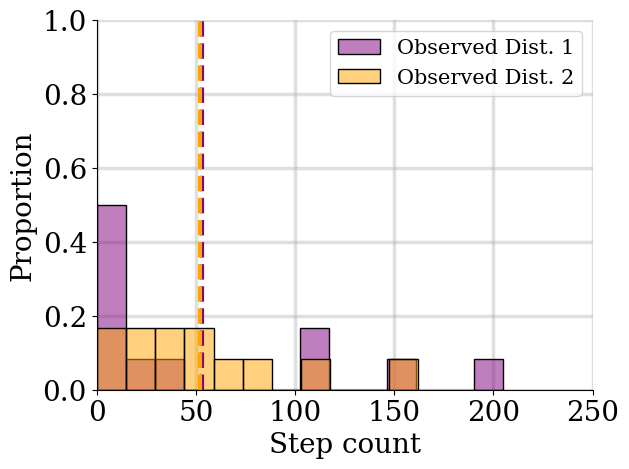

In [11]:
i, j = 0, 65
u, t = 24, 89
fig, ax1 = plt.subplots(ncols = 1)
mmd = (np.exp(mmd_KTE_estsA0[i][j]) - 1)
mmd = (np.exp(M_hs[u, t]) - 1)
mhs = (np.exp(M_hs[i, j]) - 1)
#sns.kdeplot(mmd_KTE_estsA0[i][j].squeeze(), color = "teal", ax = ax1)
#sns.kdeplot(M_hs[i, j].squeeze(), color = "orange", ax = ax1)
# sns.histplot(mmd_KTE_estsA0[i][j].squeeze(), color = "teal", alpha = 0.5, stat="proportion", bins = 20)
# sns.histplot(M_hs[i, j].squeeze(), color = "orange", alpha = 0.5, stat = "proportion", bins = 20)
sns.histplot(mmd.squeeze(), color = "purple", alpha = 0.5, stat="proportion", binwidth = 15)
sns.histplot(mhs.squeeze(), color = "orange", alpha = 0.5, stat = "proportion", binwidth = 15)
# sns.histplot([-100], color = "teal", ax = ax1)
# sns.histplot([-100], color = "orange", ax=ax1)
ax1.legend(["Observed Dist. 1"] + ["Observed Dist. 2"], fontsize = 15)
ax1.set_xlabel("Step count", fontsize = 20)
ax1.set_ylabel("Proportion", fontsize = 20)
#ax1.set_title("Same mean, different distributions")
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
print(np.nanmax(mmd))
print(np.nanmean(mmd) - np.nanmean(mhs))
# print(np.nanmean(mhs))
ax1.axvline(np.nanmean(mmd), color='purple', linestyle = "--", linewidth = 3, alpha=1) # vertical
ax1.axvline(np.nanmean(mhs), color='orange', linestyle = "--", linewidth = 3, alpha=1) # horizontal
#ax1.set_ylabel("")
#ax1.set_yticks(labels = [])
#ax1.set_xticks(labels = [] )
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
ax1.set_xlim(0, 250)
ax1.set_ylim(0, 1)
#frame1 = plt.gca()
#frame1.axes.xaxis.set_ticklabels([])
#frame1.axes.yaxis.set_ticklabels([])
#plt.show()
#ax1.set_xticks([])
#fig.suptitle("KDE of Kernel-NN$_{exp}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("hist_p2489_o065_reg.pdf", bbox_inches = "tight")


584.9999999999998
3.0403645833333357


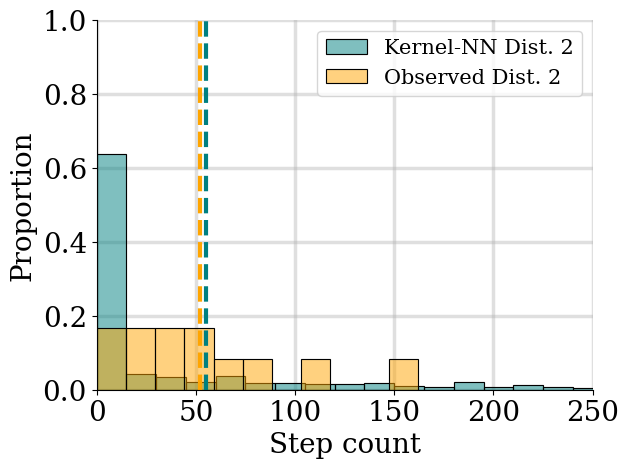

In [12]:
i, j = 0, 65
u, t = 24, 89
fig, ax1 = plt.subplots(ncols = 1)
mmd = (np.exp(mmd_KTE_estsA0[i][j]) - 1)
mhs = (np.exp(M_hs[i, j]) - 1)
#sns.kdeplot(mmd_KTE_estsA0[i][j].squeeze(), color = "teal", ax = ax1)
#sns.kdeplot(M_hs[i, j].squeeze(), color = "orange", ax = ax1)
# sns.histplot(mmd_KTE_estsA0[i][j].squeeze(), color = "teal", alpha = 0.5, stat="proportion", bins = 20)
# sns.histplot(M_hs[i, j].squeeze(), color = "orange", alpha = 0.5, stat = "proportion", bins = 20)
sns.histplot(mmd.squeeze(), color = "teal", alpha = 0.5, stat="proportion", binwidth = 15)
sns.histplot(mhs.squeeze(), color = "orange", alpha = 0.5, stat = "proportion", binwidth = 15)
# sns.histplot([-100], color = "teal", ax = ax1)
# sns.histplot([-100], color = "orange", ax=ax1)
ax1.legend(["Kernel-NN Dist. 2"] + ["Observed Dist. 2"], fontsize = 15)
ax1.set_xlabel("Step count", fontsize = 20)
ax1.set_ylabel("Proportion", fontsize = 20)
#ax1.set_title("Same mean, different distributions")
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
print(np.nanmax(mmd))
print(np.nanmean(mmd) - np.nanmean(mhs))
# print(np.nanmean(mhs))
ax1.axvline(np.nanmean(mmd), color='teal', linestyle = "--", linewidth = 3, alpha=1) # vertical
ax1.axvline(np.nanmean(mhs), color='orange', linestyle = "--", linewidth = 3, alpha=1) # horizontal
#ax1.set_ylabel("")
#ax1.set_yticks(labels = [])
#ax1.set_xticks(labels = [] )
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
ax1.set_xlim(0, 250)
ax1.set_ylim(0, 1)
#frame1 = plt.gca()
#frame1.axes.xaxis.set_ticklabels([])
#frame1.axes.yaxis.set_ticklabels([])
#plt.show()
#ax1.set_xticks([])
#fig.suptitle("KDE of Kernel-NN$_{exp}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("histi0_t65_dist2.pdf", bbox_inches = "tight")


In [ ]:
i, j = 0, 78
#print(mmd_KTE_estsA0[i][j])
#print(M_hs[i][j])
sns.kdeplot(mmd_KTE_estsA0[i][j], color = "purple", alpha = 0.75)
sns.kdeplot(M_hs[i, j], color = "teal", alpha = 0.75)

In [ ]:
len(closeinds_obvs1_cf0)

In [ ]:
KTE_obvs_exp = np.load("../data_checkpoints/kte_obvs_exp.npy", allow_pickle = True)

In [ ]:
dnn.sqmmd_est2(mmd_KTE_estsA1[0, 0], M_hs[0, 0], kernel = "exponential")

In [ ]:
l = np.nonzero(np.isnan(KTE_obvs_exp) & ~np.isnan(ate_mmd_estimates))

In [ ]:
mmd_KTE_estsA0[l[0][0]][l[1][0]]

In [ ]:
print(A_hs[l[0][0], l[1][0]])
dnn.sqmmd_est2(mmd_KTE_estsA0[l[0][0], l[1][0]], M_hs[l[0][0], l[1][0]], kernel = "exponential")

In [ ]:
np.sum(M_hs[0, 0])

In [ ]:
np.sum(A_hs[0] != 2)

In [ ]:
# KTE is -> A1 estimates (mmd) A0 observed and A0 estimates (mmd) A1 observed
# OR KTE is A1 estimates (mmd) A0 estimates

KTE_obvs_exp = np.full([N, T], np.nan)
KTE_ests_exp = np.full([N, T], np.nan)

#KTE_obvs_sq = np.full([N, T], np.nan)
#KTE_ests_sq = np.full([N, T], np.nan)

#KTE_obvs_ks_sq = np.full([N, T], np.nan)
#KTE_ests_ks_sq = np.full([N, T], np.nan)

KTE_obvs_ks_exp = np.full([N, T], np.nan)
KTE_ests_ks_exp = np.full([N, T], np.nan)

for i in range(N):
  for j in range(T):
    if A_hs[i, j] != 2:
    # if not mmd_estimates_exp_A0 is None and not mmd_estimates_exp_A1 is None:
      KTE_ests_exp[i, j] = dnn.sqmmd_est2(mmd_estimates_exp_A0[i][j], mmd_estimates_exp_A1[i][j], 
                                            kernel = "exponential")
      KTE_ests_ks_exp[i, j] = kstest(mmd_estimates_exp_A0[i][j], mmd_estimates_exp_A1[i][j]).statistic

      # if not mmd_estimates_sq_A0 is None and not mmd_estimates_sq_A1 is None:  
      # KTE_ests_sq[i, j] = dnn.sqmmd_est2(mmd_estimates_sq_A0[i][j], mmd_estimates_sq_A1[i][j],
      #                                     kernel = "square")
      #KTE_ests_ks_sq[i, j] = kstest(mmd_estimates_sq_A0[i][j], mmd_estimates_sq_A1[i][j]).statistic


      if A_hs[i, j] == 0:
        KTE_obvs_exp[i, j] = dnn.sqmmd_est2(mmd_estimates_exp_A1[i][j], M_hs[i, j],
                                            kernel = "exponential")
        # KTE_obvs_sq[i, j] = dnn.sqmmd_est2(mmd_estimates_sq_A1[i][j], M_hs[i, j],
        #                                   kernel = "square")

        KTE_obvs_ks_exp[i, j] = kstest(mmd_estimates_exp_A1[i][j], M_hs[i, j]).statistic
        # KTE_obvs_ks_sq[i, j] = kstest(mmd_estimates_sq_A1[i][j], M_hs[i, j]).statistic
      else:
        KTE_obvs_exp[i, j] = dnn.sqmmd_est2(M_hs[i, j], mmd_estimates_exp_A0[i][j],
                                            kernel = "exponential")
        # KTE_obvs_sq[i, j] = dnn.sqmmd_est2(M_hs[i, j], mmd_estimates_sq_A0[i][j],
        #                                   kernel = "square")

        KTE_obvs_ks_exp[i, j] = kstest(M_hs[i, j], mmd_estimates_exp_A0[i][j]).statistic
        # KTE_obvs_ks_sq[i, j] = kstest(M_hs[i, j], mmd_estimates_sq_A0[i][j]).statistic


  
  

In [ ]:
#np.save("kte_obvs_sq.npy", KTE_obvs_sq)
np.save("kte_obvs_exp_v2.npy", KTE_obvs_exp)
#np.save("kte_obvs_ks_sq.npy", KTE_obvs_ks_sq)
np.save("kte_obvs_ks_exp_v2.npy", KTE_obvs_ks_exp)

np.save("kte_ests_exp_v2.npy", KTE_ests_exp)
#np.save("kte_ests_sq.npy", KTE_ests_sq)
np.save("kte_ests_ks_exp_v2.npy", KTE_ests_ks_exp)
#np.save("kte_ests_ks_sq.npy", KTE_ests_ks_sq)



In [ ]:
fig, (ax1, ax2) = plt.subplots(figsize=(16, 8), nrows = 2)


pos1 = ax1.imshow(KTE_obvs_exp, aspect = 'auto')
pos2 = ax2.imshow(KTE_obvs_ks_exp, aspect = 'auto')

fig.colorbar(pos1, ax = ax1, label = "KTE$_{gaussian}$")
fig.colorbar(pos2, ax = ax2, label = "KS-test treatment effect")

ax2.set_xlabel("Decision times")
ax2.set_ylabel("Units")

ax1.set_ylabel("Units")

ax1.get_xaxis().set_ticklabels([])
ax2.get_xaxis().set_ticklabels([])

ax1.set_title("Estimated Treatment Effect - Kernel-NN$_{gaussian}$")
#ax2.set_title("Kolmogorov-Smirnov test treatment effect")
#ax3.set_title("Kernel-NN with square kernel")

#fig.suptitle("2-sample Kolmogorov-Smirnov test statistic by DNN method")
plt.savefig("kte_ks_exp.pdf", bbox_inches = "tight")

In [ ]:
len(A_hs[30][A_hs[30] == 0])


In [ ]:
KTE_obvs_exp = np.load("../data_checkpoints/kte_obvs_exp_v2.npy")

In [ ]:
# find the mean KTE across all entries

kte_mean = np.nanmean(KTE_obvs_exp)
kte_mean

In [ ]:
kte_median = np.nanmedian(KTE_obvs_exp)

In [ ]:
kte_0_nonan = KTE_obvs_exp[11][~np.isnan(KTE_obvs_exp[11])]
kte_18_nonan = KTE_obvs_exp[12][~np.isnan(KTE_obvs_exp[12])]

In [ ]:
len(kte_0_nonan)

In [ ]:
p5_11 = np.poly1d(np.polyfit(np.arange(len(kte_11_nonan)), kte_11_nonan, deg = 5))
p5_30 = np.poly1d(np.polyfit(np.arange(len(kte_30_nonan)), kte_30_nonan, deg = 5))


In [ ]:
# unit 0
# unit 11 increases, unit 10 decreases, 
# unit 30 

fig, (ax1, ax2) = plt.subplots(figsize=(20,8), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
xs1 = np.arange(len(kte_0_nonan))
y1 = kte_0_nonan
ax1.plot(xs1, y1, '.', color = "maroon")
#ax1.plot(xs1, p5_11(xs1), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax1.set_xlabel("Decision point")
ax1.set_ylabel("Estimated KTE$_{Gaussian}$")
ax1.set_title("Estimated Kernel Treatment Effect - Unit 11")

ax1.set_ylim([-0.05, 1.1])
ax2.set_ylim([-0.05, 1.1])

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)
xs2 = np.arange(len(kte_18_nonan))
y2 = kte_18_nonan
ax2.plot(xs2, y2, '.', color = "teal")
#ax2.plot(xs2, p5_30(xs2), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax2.set_xlabel("Decision point")
ax2.set_ylabel("Estimated KTE$_{Gaussian}$")
ax2.set_title("Estimated Kernel Treatment Effect - Unit 12")

ax1.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0, label = "Median KTE")
ax2.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0, label = "Median KTE")

ax2.legend()
plt.savefig("kte_intr34_exp.pdf", bbox_inches = "tight")


In [ ]:
seaborn.regplot(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0])

In [ ]:
from scipy.interpolate import CubicSpline
print(KTE_obvs_exp[0].shape)
kte_0_nonan = KTE_obvs_exp[0][~np.isnan(KTE_obvs_exp[0])]
cs = CubicSpline(np.arange(len(kte_0_nonan)), kte_0_nonan)
x_range = np.arange(len(kte_0_nonan))
plt.plot(x_range, cs(x_range), label='Cubic Spline')

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)
ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_ks_exp[0], alpha= 0.8, color = "goldenrod")
ax.set_xlabel("Day in trial")
ax.set_ylabel("Kolmogorov-Smirnov test statistic")
ax.set_title("KS-test Treatment Effect - Unit 0")

plt.savefig("kte_unit0_ks.pdf", bbox_inches = "tight")

## KTE Regression with Demographic Covariates

In [ ]:
from skimage.measure import block_reduce
import statsmodels.api as sm

In [ ]:
KTE_obvs_exp = np.load("../data_checkpoints/kte_obvs_exp.npy")

In [ ]:
user_data = pd.read_csv("../data/users.csv")


In [ ]:
print(list(user_data.columns))

In [ ]:
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [ ]:
# minus marital
keep_cols = ["user.index", "age", "gender", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [ ]:
# minus age
keep_cols = ["user.index", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [ ]:
# minus gender
keep_cols = ["user.index", "age", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

In [ ]:
agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
full_agg_KTE_obvs_exp = np.nanmean(KTE_obvs_exp, axis = 1)
df_full_agg_KTE = pd.DataFrame(full_agg_KTE_obvs_exp, columns = ["trial_kte"])
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

In [ ]:
full_agg_KTE_obvs_exp.shape

In [ ]:
df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)
df_kte_dem

In [ ]:
keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)
df_kte_drop_dums

In [ ]:
X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


In [ ]:
X_const = sm.add_constant(X)
model = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results = model.fit()

In [ ]:
results.summary()

### Feature selection using AIC/BIC scores

In [ ]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - age
keep_cols = ["user.index", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic


In [ ]:
# full model - gender
keep_cols = ["user.index", "age", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - marital
keep_cols = ["user.index", "age", "gender", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]


X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic


In [ ]:
# full model - ethnicity
keep_cols = ["user.index", "age", "gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - children
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - education
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - screentime
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - activity
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

Removed ethnicity

In [ ]:
# full model - ethnicity - age
keep_cols = ["user.index", "gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - gender
keep_cols = ["user.index", "age", "marital", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = [ "marital", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = [ "marital_married", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital
keep_cols = ["user.index", "age", "gender", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - children
keep_cols = ["user.index", "age", "gender", "marital", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - education
keep_cols = ["user.index", "age", "gender", "marital", "children", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0",  "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - screentime
keep_cols = ["user.index", "age", "gender", "marital", "children", "education", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - activity
keep_cols = ["user.index", "age", "gender", "marital", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - age
keep_cols = ["user.index", "gender", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - gender
keep_cols = ["user.index", "age", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - children
keep_cols = ["user.index", "age", "gender", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - education
keep_cols = ["user.index", "age", "gender", "children", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "screentime_1", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - screentime
keep_cols = ["user.index", "age", "gender", "children", "education",  "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "ipaq.hepa.intake_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity
keep_cols = ["user.index", "age", "gender", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

Remove ethnicity, marital, and activity

In [ ]:
# full model - ethnicity - marital - activity - age
keep_cols = ["user.index", "gender", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - gender
keep_cols = ["user.index", "age", "children", "education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["children", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["children_0", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - children
keep_cols = ["user.index", "age", "gender","education", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - education
keep_cols = ["user.index", "age", "gender", "children", "screentime"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "screentime"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "screentime_1"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime
keep_cols = ["user.index", "age", "gender", "children", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

Remove ethnicity, marital, activity, screentime

In [ ]:
# full model - ethnicity - marital - activity - screentime - age
keep_cols = ["user.index", "gender", "children", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - gender
keep_cols = ["user.index", "age", "children", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["children", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = [ "children_0", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - children
keep_cols = ["user.index", "age", "gender", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - education
keep_cols = ["user.index", "age", "gender", "children"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "children"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "children_0"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

Minus ethnicity, marital, activity, screentime, children

In [ ]:
# full model - ethnicity - marital - activity - screentime - children - age
keep_cols = ["user.index", "gender", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - children - gender
keep_cols = ["user.index", "age", "education"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - children - education
keep_cols = ["user.index", "age", "gender"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - children - education - age
keep_cols = ["user.index", "gender"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - children - education - gender
keep_cols = ["user.index", "age"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = []

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = []

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
# full model - ethnicity - marital - activity - screentime - children - education - age
keep_cols = ["user.index"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = []

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = []

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

X_const = sm.add_constant(X)
model_0_10 = sm.OLS(Y_kte_0_10, X_const.astype('float64'), missing = 'drop')
results_0_10 = model_0_10.fit()
aic_0_10 = results_0_10.aic

model_10_20 = sm.OLS(Y_kte_10_20, X_const.astype('float64'), missing = 'drop')
results_10_20 = model_10_20.fit()
aic_10_20 = results_10_20.aic

model_20_30 = sm.OLS(Y_kte_20_30, X_const.astype('float64'), missing = 'drop')
results_20_30 = model_20_30.fit()
aic_20_30 = results_20_30.aic

model_30_40 = sm.OLS(Y_kte_30_40, X_const.astype('float64'), missing = 'drop')
results_30_40 = model_30_40.fit()
aic_30_40 = results_30_40.aic

avg_aic = (aic_0_10 + aic_10_20 + aic_20_30 + aic_30_40) / 4

avg_aic

In [ ]:
print(results_20_30.summary())

Minimized AIC is the null model

In [ ]:
# fit against full averaged


### Full model on full averaged KTE

In [ ]:
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = ["gender", "marital", "ethnicity", "children", "education", "screentime", "ipaq.hepa.intake"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["gender_female", "marital_married", "ethnicity_white/caucasian", "children_0", "education_some college", "screentime_1", "ipaq.hepa.intake_1"]


In [ ]:
user_data_final["gender"]

In [ ]:
X.values.astype(int)

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values.astype(int), i) for i in range(X.shape[1])]
print(vif_data)

In [ ]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "childhome", "education", "screentime", "ipaq.hepa.intake", "office.shops", "office.pleasant", "office.sidewalk"]
user_data_final = user_data[keep_cols]

agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem = pd.concat([user_data_final, df_kte], axis = 1)

keep_cols = [ "marital", "gender", "ethnicity", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "gender_female", "ethnicity_white/caucasian", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40", "user.index"])
Y_kte_0_10 = df_kte_drop_dums["kte_0_10"]
Y_kte_10_20 = df_kte_drop_dums["kte_10_20"]
Y_kte_20_30 = df_kte_drop_dums["kte_20_30"]
Y_kte_30_40 = df_kte_drop_dums["kte_30_40"]

Y_kte = df_full_agg_KTE["trial_kte"]

X_const = sm.add_constant(X)
model = sm.OLS(Y_kte, X_const.astype('float64'), missing = 'drop')
results = model.fit()

print(results.summary())


In [ ]:
import seaborn as sns

In [ ]:
def coef_plot(results):
  """
  Plot coefficients with 95% confidence interval
  """
  # extract coef and ci from results summary
  coefs = pd.DataFrame(results.summary().tables[1].data)
  # col names are the first row
  coefs.columns = coefs.iloc[0]
  # drop the col names
  coefs = coefs.drop(0)
  coefs = coefs.set_index(coefs.columns[0])
  coefs = coefs.astype(float)
  err = coefs["coef"] - coefs["[0.025"]
  coefs["errors"] = err

  # drop const for plot
  coefs = coefs.drop(['const'])
  # sort aascending
  coefs = coefs.sort_values(by = ['coef'])
  
  vars = list(coefs.index.values)

  coefs['vars'] = vars

  sns.set_context("poster")

  fig, ax = plt.subplots(figsize = (15, 10))
  
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  coefs.plot(x = 'vars', y = 'coef', kind = "bar", 
             ax = ax, color = 'none', ecolor = 'teal', capsize = 5, 
             yerr = 'errors', legend = False)
  ax.set_title("Feature coefficients with 95% CI - Mean KTE regression")
  ax.set_ylabel("Coefficients")
  ax.set_xlabel("Features")

  plt.xticks(rotation=60, ha='right')

  ax.scatter(x = np.arange(coefs.shape[0]),
             marker = 'o', s = 80, y = coefs['coef'], color = 'teal')
  # line at 0
  ax.axhline(y=0, linestyle = '--', color = 'orange', linewidth = 1)  
  ax.grid(True, alpha=0.4)

  plt.savefig("kte_regression_coefs_mean.pdf", bbox_inches = "tight")


In [ ]:
coef_plot(results)

## Interestingness

In [ ]:
KTE_obvs_exp = np.load('../data_checkpoints/kte_obvs_exp_v2.npy')

In [ ]:
# find the mean KTE across all entries

kte_mean = np.nanmean(KTE_obvs_exp)
kte_mean

In [ ]:
kte_median = np.nanmedian(KTE_obvs_exp)
kte_median

In [ ]:
split_kte =np.split(KTE_obvs_exp, 2, axis = 1)
beg_kte = split_kte[0]
end_kte = split_kte[1]


In [ ]:
beg_kte_gt_median = beg_kte > kte_median
end_kte_gt_median = end_kte > kte_median

beg_kte_lt_median = beg_kte < kte_median
end_kte_lt_median = end_kte < kte_median

count_beg_kte_gt_median = np.sum(beg_kte_gt_median, axis = 1)
count_end_kte_gt_median = np.sum(end_kte_gt_median, axis = 1)

count_beg_kte_lt_median = np.sum(beg_kte_lt_median, axis = 1)
count_end_kte_lt_median = np.sum(end_kte_lt_median, axis = 1)

count_beg_kte_gt_median


In [ ]:
beg_kte_total_nonan = np.sum(~np.isnan(beg_kte), axis = 1)
end_kte_total_nonan = np.sum(~np.isnan(end_kte), axis = 1)

beg_kte_gt_prop = count_beg_kte_gt_median / beg_kte_total_nonan
end_kte_gt_prop = count_end_kte_gt_median / end_kte_total_nonan

beg_kte_lt_prop = count_beg_kte_lt_median / beg_kte_total_nonan
end_kte_lt_prop = count_end_kte_lt_median / end_kte_total_nonan

In [ ]:
# interestingness 1
inds_i1 = np.nonzero((beg_kte_gt_prop > 0.6) & (end_kte_gt_prop > 0.6))
inds_i2 = np.nonzero((beg_kte_lt_prop > 0.6) & (end_kte_lt_prop > 0.6))
inds_i3 = np.nonzero((beg_kte_gt_prop < 0.5) & (end_kte_gt_prop > 0.5))
inds_i4 = np.nonzero((beg_kte_lt_prop < 0.5) & (end_kte_lt_prop > 0.5))
print(inds_i1)
print(inds_i2)
print(inds_i3)
print(inds_i4)

In [ ]:
# inds_i1-4 represent the "interesting" cohort. 
# we regress wrt to the binary outcome for each of them
is_intr_1 = np.zeros(N)
is_intr_1[inds_i1] = 1

is_intr_2 = np.zeros(N)
is_intr_2[inds_i2] = 1

is_intr_3 = np.zeros(N) 
is_intr_3[inds_i3] = 1

is_intr_4 = np.zeros(N)
is_intr_4[inds_i4] = 1



In [ ]:
# Interestingness with magnitude
# compute residuals wrt to the median for the first and second halves

beg_kte_resid_mean = np.nanmean(beg_kte - kte_mean, axis = 1)
end_kte_resid_mean = np.nanmean(end_kte - kte_mean, axis = 1)

end_kte_resid_mean

In [ ]:
inds_resid_i1 = np.nonzero((beg_kte_resid_mean > 0.05) & (end_kte_resid_mean > 0.05))
inds_resid_i2 = np.nonzero((beg_kte_resid_mean < -0.05) & (end_kte_resid_mean < -0.05))
inds_resid_i3 = np.nonzero((beg_kte_resid_mean < 0) & (end_kte_resid_mean > 0))
inds_resid_i4 = np.nonzero((beg_kte_resid_mean > 0) & (end_kte_resid_mean < 0))

print(inds_resid_i1)
print(inds_resid_i2)
print(inds_resid_i3)
print(inds_resid_i4)


In [ ]:
kte_0_nonan = KTE_obvs_exp[12][~np.isnan(KTE_obvs_exp[12])]
kte_18_nonan = KTE_obvs_exp[13][~np.isnan(KTE_obvs_exp[13])]

In [ ]:
# unit 0
# unit 11 increases, unit 10 decreases, 
# unit 30 

fig, (ax1, ax2) = plt.subplots(figsize=(20,8), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
xs1 = np.arange(len(kte_0_nonan))
y1 = kte_0_nonan
ax1.plot(xs1, y1, '.', color = "maroon")
#ax1.plot(xs1, p5_11(xs1), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax1.set_xlabel("Decision point")
ax1.set_ylabel("Estimated KTE$_{Gaussian}$")
ax1.set_title("Estimated Kernel Treatment Effect - Unit 25")

ax1.set_ylim([-0.05, 1.1])
ax2.set_ylim([-0.05, 1.1])

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)
xs2 = np.arange(len(kte_18_nonan))
y2 = kte_18_nonan
ax2.plot(xs2, y2, '.', color = "teal")
#ax2.plot(xs2, p5_30(xs2), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax2.set_xlabel("Decision point")
ax2.set_ylabel("Estimated KTE$_{Gaussian}$")
ax2.set_title("Estimated Kernel Treatment Effect - Unit 13")

ax1.axhline(kte_mean, linestyle='--', color = "red", linewidth = 4.0, label = "Mean KTE")
ax2.axhline(kte_mean, linestyle='--', color = "red", linewidth = 4.0, label = "Mean KTE")

ax2.legend()
plt.savefig("kte_resid34_exp.pdf", bbox_inches = "tight")


In [ ]:
is_resid_1 = np.zeros(N)
is_resid_1[inds_resid_i1] = 1

is_resid_2 = np.zeros(N)
is_resid_2[inds_resid_i2] = 1

is_resid_3 = np.zeros(N) 
is_resid_3[inds_resid_i3] = 1

is_resid_4 = np.zeros(N)
is_resid_4[inds_resid_i4] = 1

In [ ]:
user_data = pd.read_csv("../data/users.csv")


In [ ]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "childhome", "education", "screentime", "ipaq.hepa.intake", "office.shops", "office.pleasant", "office.sidewalk", "phonecomfort"]
df_kte_dem = user_data[keep_cols]

#agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
#df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem["intr_1"] = is_intr_1
df_kte_dem["intr_2"] = is_intr_2
df_kte_dem["intr_3"] = is_intr_3
df_kte_dem["intr_4"] = is_intr_4

df_kte_dem["resid_1"] = is_resid_1
df_kte_dem["resid_2"] = is_resid_2
df_kte_dem["resid_3"] = is_resid_3
df_kte_dem["resid_4"] = is_resid_4


keep_cols = [ "marital", "gender", "ethnicity", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "gender_female", "ethnicity_white/caucasian", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["intr_1", "intr_2", "intr_3", "intr_4", 
                                     "resid_1", "resid_2", "resid_3", "resid_4", 
                                     "user.index"])

Y_kte_intr_1 = df_kte_drop_dums["intr_1"]
Y_kte_intr_2 = df_kte_drop_dums["intr_2"]
Y_kte_intr_3 = df_kte_drop_dums["intr_3"]
Y_kte_intr_4 = df_kte_drop_dums["intr_4"]

Y_kte_resid_1 = df_kte_drop_dums["resid_1"]
Y_kte_resid_2 = df_kte_drop_dums["resid_2"]
Y_kte_resid_3 = df_kte_drop_dums["resid_3"]
Y_kte_resid_4 = df_kte_drop_dums["resid_4"]

#Y_kte = df_full_agg_KTE["trial_kte"]

X_const = sm.add_constant(X)
model = sm.OLS(Y_kte_resid_4, X_const.astype('float64'), missing = 'drop')
results = model.fit()

print(results.summary())

In [ ]:
X

In [ ]:
def coef_plot(results):
  """
  Plot coefficients with 95% confidence interval
  """
  # extract coef and ci from results summary
  coefs = pd.DataFrame(results.summary().tables[1].data)
  # col names are the first row
  coefs.columns = coefs.iloc[0]
  # drop the col names
  coefs = coefs.drop(0)
  coefs = coefs.set_index(coefs.columns[0])
  coefs = coefs.astype(float)
  err = coefs["coef"] - coefs["[0.025"]
  coefs["errors"] = err

  # drop const for plot
  coefs = coefs.drop(['const'])
  # sort aascending
  coefs = coefs.sort_values(by = ['coef'])
  
  vars = list(coefs.index.values)

  coefs['vars'] = vars

  sns.set_context("poster")

  fig, ax = plt.subplots(figsize = (15, 10))
  
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  coefs.plot(x = 'vars', y = 'coef', kind = "bar", 
             ax = ax, color = 'none', ecolor = 'teal', capsize = 5, 
             yerr = 'errors', legend = False)
  ax.set_title("Feature coefficients with 95% CI - Residual Type 4 logit")
  ax.set_ylabel("Coefficients")
  ax.set_xlabel("Features")

  plt.xticks(rotation=60, ha='right')

  ax.scatter(x = np.arange(coefs.shape[0]),
             marker = 'o', s = 80, y = coefs['coef'], color = 'teal')
  # line at 0
  ax.axhline(y=0, linestyle = '--', color = 'orange', linewidth = 1)  
  ax.grid(True, alpha=0.4)
  plt.savefig("kte_logits_coefs_resid4.pdf", bbox_inches = "tight")


In [ ]:
coef_plot(results)

### Computing Entry-level Average Treatment Effect

In [ ]:
mmd_estimates_exp_A1 = np.load("../data_checkpoints/mmd_exp_fullestimatesA1_v20_log.npy", allow_pickle = True)
mmd_estimates_exp_A0 = np.load("../data_checkpoints/mmd_exp_fullestimatesA0_v20_log.npy", allow_pickle = True)

In [ ]:
mean_mmd_estimates_exp_A1 = np.full([N, T], np.nan)
mean_mmd_estimates_exp_A0 = np.full([N, T], np.nan)

for i in range(N):
  for j in range(T):
    if A_hs[i, j] != 2:
      mean_mmd_estimates_exp_A1[i, j] = np.nanmean(mmd_estimates_exp_A1[i][j], axis = 0)
      mean_mmd_estimates_exp_A0[i, j] = np.nanmean(mmd_estimates_exp_A0[i][j], axis = 0)


In [ ]:
dnn.sqmmd_est2(np.array([[np.nan], [1.], [2.]]), np.array([[np.nan], [3.], [9.]]), kernel = "exponential")

In [ ]:
ate_mmd_estimates = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    if A_hs[i, j] != 2:
      if A_hs[i, j] == 1:
        ate_mmd_estimates[i, j] = mean_mmd_estimates_exp_A0[i][j] - M_hs_log_mean[i, j]
      else:
        ate_mmd_estimates[i, j] = mean_mmd_estimates_exp_A1[i][j] - M_hs_log_mean[i, j]



In [ ]:
np.sum(ate_mmd_estimates < 0)

Defining interestingness wrt to scalar ATE

1. Type 1: fraction of positive ATE is greater than some threshold for both the first half and second half of the study (positive effect)
2. Type 2: fraction of positive ATE is less than some threshold for both the first half and second half of the study (negative effect)
   1. Since we think our treatment will have 0 ate at minimum, having 0.5 proportion of negative ate is sufficient for "interesting"
3. Type 3: fraction of negative ATE is greater than some threshold for the first half but below some threshold for the second half (increasing effect)
4. Type 4: fraction of positive ATE is greater than some threshold for the first half but below some threshold for the second half (decreasing effect)

In [ ]:
ate_0_nonan = ate_mmd_estimates[0][~np.isnan(ate_mmd_estimates[0])]
ate_0_nonan = ate_0_nonan[0:105]
ate_18_nonan = ate_mmd_estimates[12][~np.isnan(ate_mmd_estimates[12])]
ate_18_nonan = ate_18_nonan[0:105]

In [ ]:
len(ate_0_nonan)

In [ ]:
len(kte_0_nonan)

In [ ]:
fig, (ax1, ax2) = plt.subplots(figsize=(20,8), ncols = 2)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
xs1 = np.arange(len(kte_0_nonan))
y1 = kte_0_nonan
ax1.plot(xs1, y1, '.', color = "purple")
#ax1.plot(xs1, p5_11(xs1), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax1.set_xlabel("Decision point")
ax1.set_ylabel("Estimated entry-level KTE")
ax1.set_title("Estimated Kernel Treatment Effect - Unit 12")

ax2.set_xlim([-6, 106])
#ax2.set_ylim([0, 1.1])

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)
xs2 = np.arange(len(ate_18_nonan))
y2 = ate_18_nonan
ax2.plot(xs2, y2, '.', color = "green")
#ax2.plot(xs2, p5_30(xs2), '-', color = "orange")
#ax.scatter(x = np.arange(len(KTE_obvs_exp[0])), y = KTE_obvs_exp[0], alpha= 0.8, color = "darkgreen")
ax2.set_xlabel("Decision point")
ax2.set_ylabel("Estimated entry-level ATE")
ax2.set_title("Estimated Average Treatment Effect - Unit 12")

#plt.show()
#ax1.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0)
#ax2.axhline(kte_median, linestyle='--', color = "orange", linewidth = 4.0)
plt.savefig("kte_ate_unit12_exp.pdf", bbox_inches = "tight")


In [ ]:
ate_mmd_estimates.shape

In [ ]:
split_ate = np.split(ate_mmd_estimates, 2, axis = 1)
beg_ate = split_ate[0]
end_ate = split_ate[1]

pos_beg_ate = np.sum(beg_ate > 0, axis = 1)
pos_end_ate = np.sum(end_ate > 0, axis = 1)

neg_beg_ate = np.sum(beg_ate < 0, axis = 1)
neg_end_ate = np.sum(end_ate < 0, axis = 1)

tot_beg_ate = np.sum(~np.isnan(beg_ate), axis = 1)
tot_end_ate = np.sum(~np.isnan(end_ate), axis = 1)

pos_beg_ate_prop = pos_beg_ate / tot_beg_ate
pos_end_ate_prop = pos_end_ate / tot_end_ate

neg_beg_ate_prop = neg_beg_ate / tot_beg_ate
neg_end_ate_prop = neg_end_ate / tot_end_ate

pos_beg_ate_prop


In [ ]:
print(pos_beg_ate_prop)
print(pos_end_ate_prop)

In [ ]:
inds_ate_intr1 = np.nonzero((pos_beg_ate_prop > 0.55) & (pos_end_ate_prop > 0.55))
inds_ate_intr2 = np.nonzero((neg_beg_ate_prop > 0.5) & (neg_end_ate_prop > 0.5))
inds_ate_intr3 = np.nonzero((neg_beg_ate_prop > 0.5) & (pos_end_ate_prop > 0.5))
inds_ate_intr4 = np.nonzero((pos_beg_ate_prop > 0.5) & (neg_end_ate_prop > 0.5))

print(inds_ate_intr1)
print(inds_ate_intr2)
print(inds_ate_intr3)
print(inds_ate_intr4)

In [ ]:
is_ate_1 = np.zeros(N)
is_ate_1[inds_ate_intr1] = 1

is_ate_2 = np.zeros(N)
is_ate_2[inds_ate_intr2] = 1

is_ate_3 = np.zeros(N) 
is_ate_3[inds_ate_intr3] = 1

is_ate_4 = np.zeros(N)
is_ate_4[inds_ate_intr4] = 1

In [ ]:
Y_ate_intr_2

In [ ]:
# full model
keep_cols = ["user.index", "age", "gender", "marital", "ethnicity", "childhome", "education", "screentime", "ipaq.hepa.intake", "office.shops", "office.pleasant", "office.sidewalk", "phonecomfort"]
df_kte_dem = user_data[keep_cols]

#agg_KTE_obvs_exp = block_reduce(KTE_obvs_exp, block_size = (1, 50), func = np.nanmean)
#df_kte = pd.DataFrame(agg_KTE_obvs_exp, columns = ["kte_0_10", "kte_10_20", "kte_20_30", "kte_30_40"])

df_kte_dem["intr_1"] = is_intr_1
df_kte_dem["intr_2"] = is_intr_2
df_kte_dem["intr_3"] = is_intr_3
df_kte_dem["intr_4"] = is_intr_4

df_kte_dem["resid_1"] = is_resid_1
df_kte_dem["resid_2"] = is_resid_2
df_kte_dem["resid_3"] = is_resid_3
df_kte_dem["resid_4"] = is_resid_4

df_kte_dem["ate_1"] = is_ate_1
df_kte_dem["ate_2"] = is_ate_2
df_kte_dem["ate_3"] = is_ate_3
df_kte_dem["ate_4"] = is_ate_4


keep_cols = [ "marital", "gender", "ethnicity", "education"]

df_kte_dem_dummies = pd.get_dummies(df_kte_dem, columns = keep_cols, drop_first = False)

drop_dums = ["marital_married", "gender_female", "ethnicity_white/caucasian", "education_some college"]

df_kte_drop_dums = df_kte_dem_dummies.drop(columns = drop_dums)

X = df_kte_drop_dums.drop(columns = ["intr_1", "intr_2", "intr_3", "intr_4", 
                                     "resid_1", "resid_2", "resid_3", "resid_4",
                                     "ate_1", "ate_2", "ate_3", "ate_4", 
                                     "user.index"])

Y_kte_intr_1 = df_kte_drop_dums["intr_1"]
Y_kte_intr_2 = df_kte_drop_dums["intr_2"]
Y_kte_intr_3 = df_kte_drop_dums["intr_3"]
Y_kte_intr_4 = df_kte_drop_dums["intr_4"]

Y_kte_resid_1 = df_kte_drop_dums["resid_1"]
Y_kte_resid_2 = df_kte_drop_dums["resid_2"]
Y_kte_resid_3 = df_kte_drop_dums["resid_3"]
Y_kte_resid_4 = df_kte_drop_dums["resid_4"]

Y_ate_intr_1 = df_kte_drop_dums["ate_1"]
Y_ate_intr_2 = df_kte_drop_dums["ate_2"]
Y_ate_intr_3 = df_kte_drop_dums["ate_3"]
Y_ate_intr_4 = df_kte_drop_dums["ate_4"]

#Y_kte = df_full_agg_KTE["trial_kte"]

X_const = sm.add_constant(X)
model = sm.OLS(Y_ate_intr_4, X_const.astype('float64'), missing = 'drop')
results = model.fit()

print(results.summary())

In [ ]:
def coef_plot(results):
  """
  Plot coefficients with 95% confidence interval
  """
  # extract coef and ci from results summary
  coefs = pd.DataFrame(results.summary().tables[1].data)
  # col names are the first row
  coefs.columns = coefs.iloc[0]
  # drop the col names
  coefs = coefs.drop(0)
  coefs = coefs.set_index(coefs.columns[0])
  coefs = coefs.astype(float)
  err = coefs["coef"] - coefs["[0.025"]
  coefs["errors"] = err

  # drop const for plot
  coefs = coefs.drop(['const'])
  # sort aascending
  coefs = coefs.sort_values(by = ['coef'])
  
  vars = list(coefs.index.values)

  coefs['vars'] = vars

  sns.set_context("poster")

  fig, ax = plt.subplots(figsize = (15, 10))
  
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)

  coefs.plot(x = 'vars', y = 'coef', kind = "bar", 
             ax = ax, color = 'none', ecolor = 'teal', capsize = 5, 
             yerr = 'errors', legend = False)
  ax.set_title("Feature coefficients with 95% CI - ATE Type 4 logit")
  ax.set_ylabel("Coefficients")
  ax.set_xlabel("Features")

  plt.xticks(rotation=60, ha='right')

  ax.scatter(x = np.arange(coefs.shape[0]),
             marker = 'o', s = 80, y = coefs['coef'], color = 'teal')
  # line at 0
  ax.axhline(y=0, linestyle = '--', color = 'orange', linewidth = 1)  
  ax.grid(True, alpha=0.4)
  plt.savefig("ate_logits_coefs_intr4.pdf", bbox_inches = "tight")

In [ ]:
coef_plot(results)